In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Bachelor Thesis - Data Exploration")
print("Bibliotekat u importuan me sukses!")

Matplotlib is building the font cache; this may take a moment.


Bachelor Thesis - Data Exploration
Bibliotekat u importuan me sukses!


In [3]:
project_path = Path.cwd()

if project_path.name == "notebooks":
    project_path = project_path.parent

data_path = project_path / "data" / "raw"

print("Project:", project_path)
print("\nCSV files found:")

for file in data_path.rglob("*.csv"):
    print(file.relative_to(project_path))

Project: c:\Projects\Bachelor-Thesis

CSV files found:
data\raw\Disease Prediction Using Machine Learning\Testing.csv
data\raw\Disease Prediction Using Machine Learning\Training.csv
data\raw\Symptom2Disease\Symptom2Disease.csv


In [4]:
training_path = data_path / "Disease Prediction Using Machine Learning" / "Training.csv"
testing_path = data_path / "Disease Prediction Using Machine Learning" / "Testing.csv"

df_train = pd.read_csv(training_path)
df_test = pd.read_csv(testing_path)

print("Training dataset:", df_train.shape)
print("Testing dataset:", df_test.shape)

display(df_train.head())

Training dataset: (4920, 134)
Testing dataset: (42, 133)


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis,Unnamed: 133
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN


In [5]:
print("Numri i rreshtave:", df_train.shape[0])
print("Numri i kolonave:", df_train.shape[1])

print("\nMissing values:")
print(df_train.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_train.duplicated().sum())

print("\nEmrat e kolonave:")
print(df_train.columns.tolist())

print("\nNumri i semundjeve:")
print(df_train["prognosis"].nunique())

print("\nShperndarja e semundjeve:")
print(df_train["prognosis"].value_counts())

Numri i rreshtave: 4920
Numri i kolonave: 134

Missing values:
4920

Duplicate rows:
4616

Emrat e kolonave:
['itching', 'skin_rash', 'nodal_skin_eruptions', 'continuous_sneezing', 'shivering', 'chills', 'joint_pain', 'stomach_pain', 'acidity', 'ulcers_on_tongue', 'muscle_wasting', 'vomiting', 'burning_micturition', 'spotting_ urination', 'fatigue', 'weight_gain', 'anxiety', 'cold_hands_and_feets', 'mood_swings', 'weight_loss', 'restlessness', 'lethargy', 'patches_in_throat', 'irregular_sugar_level', 'cough', 'high_fever', 'sunken_eyes', 'breathlessness', 'sweating', 'dehydration', 'indigestion', 'headache', 'yellowish_skin', 'dark_urine', 'nausea', 'loss_of_appetite', 'pain_behind_the_eyes', 'back_pain', 'constipation', 'abdominal_pain', 'diarrhoea', 'mild_fever', 'yellow_urine', 'yellowing_of_eyes', 'acute_liver_failure', 'fluid_overload', 'swelling_of_stomach', 'swelled_lymph_nodes', 'malaise', 'blurred_and_distorted_vision', 'phlegm', 'throat_irritation', 'redness_of_eyes', 'sinus_

In [6]:
df_train_clean = df_train.drop(
    columns=["Unnamed: 133"],
    errors="ignore"
).copy()

df_test_clean = df_test.drop(
    columns=["Unnamed: 133"],
    errors="ignore"
).copy()

print("Training:", df_train_clean.shape)
print("Testing:", df_test_clean.shape)

print("Missing values (Training):",
      df_train_clean.isnull().sum().sum())

print("Duplicate rows (Training):",
      df_train_clean.duplicated().sum())

Training: (4920, 133)
Testing: (42, 133)
Missing values (Training): 0
Duplicate rows (Training): 4616


In [7]:
total_rows = len(df_train_clean)

unique_rows = len(
    df_train_clean.drop_duplicates()
)

duplicates = df_train_clean.duplicated().sum()

print("Total rows:", total_rows)
print("Unique rows:", unique_rows)
print("Duplicates:", duplicates)

print("Duplicate percentage:",
      round(duplicates / total_rows * 100, 2), "%")

Total rows: 4920
Unique rows: 304
Duplicates: 4616
Duplicate percentage: 93.82 %


In [8]:
train_columns = set(df_train_clean.columns)
test_columns = set(df_test_clean.columns)

print("Same columns:",
      train_columns == test_columns)

if train_columns == test_columns:
    test_aligned = df_test_clean[df_train_clean.columns]

    train_tuples = set(
        df_train_clean.itertuples(index=False, name=None)
    )

    overlap = sum(
        row in train_tuples
        for row in test_aligned.itertuples(index=False, name=None)
    )

    print("Testing rows:", len(test_aligned))
    print("Identical rows found in Training:", overlap)
else:
    print("Columns only in Training:",
          train_columns - test_columns)
    print("Columns only in Testing:",
          test_columns - train_columns)

Same columns: True
Testing rows: 42
Identical rows found in Training: 41


Analiza e Symptom2Disease

In [9]:
symptom_path = data_path / "Symptom2Disease" / "Symptom2Disease.csv"

df_symptoms = pd.read_csv(symptom_path)

print("Dataset shape:", df_symptoms.shape)

print("\nFirst 5 rows:")
display(df_symptoms.head())

print("\nColumn names:")
print(df_symptoms.columns.tolist())

print("\nMissing values:")
print(df_symptoms.isnull().sum())

print("\nDuplicate rows:")
print(df_symptoms.duplicated().sum())

Dataset shape: (1200, 3)

First 5 rows:


,Unnamed: 0,label,text
0,0,Psoriasis,I have been experiencing a skin rash on my arm...
1,1,Psoriasis,"My skin has been peeling, especially on my kne..."
2,2,Psoriasis,I have been experiencing joint pain in my fing...
3,3,Psoriasis,"There is a silver like dusting on my skin, esp..."
4,4,Psoriasis,"My nails have small dents or pits in them, and..."



Column names:
['Unnamed: 0', 'label', 'text']

Missing values:
Unnamed: 0    0
label         0
text          0
dtype: int64

Duplicate rows:
0


In [10]:
print("Numri i semundjeve:")
print(df_symptoms["label"].nunique())

print("\nShperndarja e semundjeve:")
print(df_symptoms["label"].value_counts())

print("\nShembuj te pershkrimeve:")
for text in df_symptoms["text"].head(5):
    print("-", text)
    print()

Numri i semundjeve:
24

Shperndarja e semundjeve:
label
Psoriasis                          50
Varicose Veins                     50
Typhoid                            50
Chicken pox                        50
Impetigo                           50
Dengue                             50
Fungal infection                   50
Common Cold                        50
Pneumonia                          50
Dimorphic Hemorrhoids              50
Arthritis                          50
Acne                               50
Bronchial Asthma                   50
Hypertension                       50
Migraine                           50
Cervical spondylosis               50
Jaundice                           50
Malaria                            50
urinary tract infection            50
allergy                            50
gastroesophageal reflux disease    50
drug reaction                      50
peptic ulcer disease               50
diabetes                           50
Name: count, dtype: int64

Shemb

In [11]:
print("Dataset shape:", df_symptoms.shape)

print("\nMissing values per column:")
print(df_symptoms.isnull().sum())

print("\nDuplicate rows:")
print(df_symptoms.duplicated().sum())

print("\nDuplicate texts:")
print(df_symptoms["text"].duplicated().sum())

print("\nEmpty texts:")
print(df_symptoms["text"].fillna("").str.strip().eq("").sum())

Dataset shape: (1200, 3)

Missing values per column:
Unnamed: 0    0
label         0
text          0
dtype: int64

Duplicate rows:
0

Duplicate texts:
47

Empty texts:
0


count    1200.000000
mean       30.725000
std         6.707225
min        12.000000
25%        26.000000
50%        30.000000
75%        35.000000
max        55.000000
Name: word_count, dtype: float64


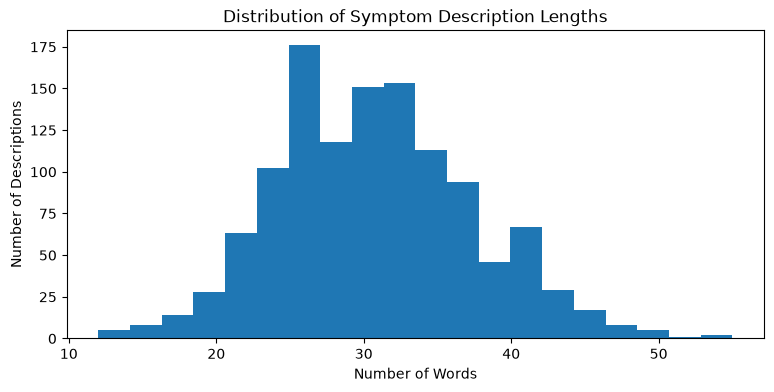

In [12]:
df_symptoms["word_count"] = (
    df_symptoms["text"]
    .fillna("")
    .str.split()
    .str.len()
)

print(df_symptoms["word_count"].describe())

plt.figure(figsize=(9, 4))
plt.hist(df_symptoms["word_count"], bins=20)
plt.title("Distribution of Symptom Description Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Descriptions")
plt.show()

In [13]:
duplicates = df_symptoms[
    df_symptoms.duplicated(subset=["text"], keep=False)
].sort_values("text")

print("Rows with repeated texts:", len(duplicates))

display(
    duplicates[["label", "text"]].head(10)
)

Rows with repeated texts: 90


,label,text
556,Acne,A nasty rash has just appeared on my skin. Bla...
563,Acne,A nasty rash has just appeared on my skin. Bla...
560,Acne,A skin rash with several pus-filled pimples an...
580,Acne,A skin rash with several pus-filled pimples an...
738,Migraine,"Along with excessive appetite, a stiff neck, h..."
737,Migraine,"Along with excessive appetite, a stiff neck, h..."
773,Cervical spondylosis,"Back pain, a persistent cough, and numbness in..."
778,Cervical spondylosis,"Back pain, a persistent cough, and numbness in..."
1048,gastroesophageal reflux disease,Even when I don't have anything acidic in my s...
1033,gastroesophageal reflux disease,Even when I don't have anything acidic in my s...


In [14]:
label_counts = (
    df_symptoms.groupby("text")["label"]
    .nunique()
)

conflicting_texts = label_counts[
    label_counts > 1
]

print("Texts with conflicting labels:",
      len(conflicting_texts))

if len(conflicting_texts) > 0:
    display(
        df_symptoms[
            df_symptoms["text"].isin(
                conflicting_texts.index
            )
        ][["label", "text"]]
        .sort_values("text")
    )

Texts with conflicting labels: 0


In [15]:
df_symptoms_clean = df_symptoms[
    ["label", "text"]
].copy()

df_symptoms_clean["label"] = (
    df_symptoms_clean["label"].str.strip()
)

df_symptoms_clean["text"] = (
    df_symptoms_clean["text"].str.strip()
)

print("Original shape:", df_symptoms.shape)
print("Clean shape:", df_symptoms_clean.shape)

display(df_symptoms_clean.head())

Original shape: (1200, 4)
Clean shape: (1200, 2)


,label,text
0,Psoriasis,I have been experiencing a skin rash on my arm...
1,Psoriasis,"My skin has been peeling, especially on my kne..."
2,Psoriasis,I have been experiencing joint pain in my fing...
3,Psoriasis,"There is a silver like dusting on my skin, esp..."
4,Psoriasis,"My nails have small dents or pits in them, and..."


In [16]:
df_symptoms_clean = (
    df_symptoms_clean
    .drop_duplicates(subset=["text"], keep="first")
    .reset_index(drop=True)
)

print("Rreshta pas Data Cleaning:",
      len(df_symptoms_clean))

print("Duplikime të mbetura:",
      df_symptoms_clean["text"].duplicated().sum())

print("Numri i klasave:",
      df_symptoms_clean["label"].nunique())

print("\nShperndarja e klasave:")
print(df_symptoms_clean["label"].value_counts())

Rreshta pas Data Cleaning: 1153
Duplikime të mbetura: 0
Numri i klasave: 24

Shperndarja e klasave:
label
Psoriasis                          50
Varicose Veins                     50
Typhoid                            50
Impetigo                           50
Dengue                             50
Fungal infection                   50
Hypertension                       50
urinary tract infection            50
allergy                            50
drug reaction                      50
peptic ulcer disease               50
diabetes                           50
Chicken pox                        49
Common Cold                        49
Bronchial Asthma                   49
Cervical spondylosis               49
gastroesophageal reflux disease    48
Pneumonia                          47
Migraine                           47
Arthritis                          46
Acne                               46
Malaria                            44
Dimorphic Hemorrhoids              41
Jaundice            

In [17]:
processed_path = project_path / "data" / "processed"
processed_path.mkdir(parents=True, exist_ok=True)

output_file = processed_path / "symptom2disease_clean.csv"

df_symptoms_clean.to_csv(
    output_file,
    index=False,
    encoding="utf-8"
)

print("Dataset saved:", output_file)

Dataset saved: c:\Projects\Bachelor-Thesis\data\processed\symptom2disease_clean.csv
